# LightGBM Zone Quality Model — Training & Evaluation Pipeline

This notebook trains a LightGBM binary classifier on historical DBR/RBR chart patterns to predict zone quality (`label: 1` = Accepted, `0` = Rejected).

### Pipeline Structure:
1. **Install dependencies**
2. **Imports**
3. **Upload / Load `dataset.csv`**
4. **Feature Engineering** (inlined, clear and explicit)
5. **Pre-training Diagnostics** (yearly acceptance consistency & label balance)
6. **Time-based Train/Test Split** (Train $\le$ 2023, Test $\ge$ 2024)
7. **5-Fold Time-Series Cross-Validation Setup**
8. **Train LightGBM Model**
9. **Evaluate & Performance Report** (Baseline comparison, train vs test metrics, confusion matrix, classification report)
10. **Feature Importance Visualization**
11. **Save & Download `model.txt`**

## 1. Install Dependencies

In [1]:
!pip install lightgbm scikit-learn matplotlib pandas numpy

## 2. Imports

In [2]:
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)
from sklearn.model_selection import TimeSeriesSplit

# Optional Google Colab file upload/download utility
try:
    from google.colab import files
except ImportError:
    files = None

## 3. Load dataset.csv

Loads `dataset.csv`. If it is not found in the Colab session, it automatically prompts you with a file upload button.

In [3]:
dataset_file_path = 'dataset.csv'

# If running in Google Colab and dataset.csv is missing, prompt to upload automatically
if not os.path.exists(dataset_file_path):
    if files is not None:
        print('dataset.csv was not found in the session. Please choose and upload dataset.csv:')
        uploaded = files.upload()
    else:
        raise FileNotFoundError(f'Could not find {dataset_file_path}. Please place dataset.csv in the current working directory.')

raw_dataset_df = pd.read_csv(dataset_file_path)
print(f'Successfully loaded dataset with {len(raw_dataset_df)} rows and {len(raw_dataset_df.columns)} columns.')

dataset.csv was not found in the session. Please choose and upload dataset.csv:


Saving dataset.csv to dataset.csv
Successfully loaded dataset with 2230 rows and 37 columns.


## 4. Feature Engineering

Extract scale-independent indicators, timing attributes, and candle dynamics directly from the raw data and `ohlcv_json` strings.

In [4]:
def extract_features(df_raw):
    df = df_raw.copy()

    # Step 1: Drop exact duplicate rows
    row_count_before = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    dropped_rows = row_count_before - len(df)
    if dropped_rows > 0:
        print(f'Dropped {dropped_rows} duplicate row(s)')

    # Step 2: Parse timestamps for time-based features
    df['start_dt'] = pd.to_datetime(df['start_timestamp'])
    df['end_dt'] = pd.to_datetime(df['end_timestamp'])
    df['year'] = df['end_dt'].dt.year

    # Step 3: Time features
    df['hour_of_day'] = df['end_dt'].dt.hour
    df['day_of_week'] = df['end_dt'].dt.dayofweek  # 0 = Monday, 4 = Friday

    # Step 4: Volatility context
    df['atr_trend'] = df['atr_at_end'] / df['atr_at_start'].replace(0, np.nan)

    # Step 5: Normalized / scale-independent features
    df['zone_range_pct'] = df['zone_range'] / df['zone_open'].replace(0, np.nan)
    df['leg_in_body_pct_of_price'] = df['leg_in_body'] / df['zone_open'].replace(0, np.nan)
    df['gap_size_pct'] = df['gap_size'] / df['zone_open'].replace(0, np.nan)
    df['adjusted_leg_out_body_pct'] = df['adjusted_leg_out_body'] / df['zone_open'].replace(0, np.nan)

    # Step 6: Interaction & strength ratios
    df['boring_vs_leg_in_strength'] = df['boring_body'] / df['leg_in_body'].replace(0, np.nan)
    df['rally_dominance'] = df['adjusted_leg_out_body'] / (df['leg_in_body'] + df['boring_body']).replace(0, np.nan)
    df['leg_out_body_vs_leg_in_body'] = df['adjusted_leg_out_body'] / df['leg_in_body'].replace(0, np.nan)

    # Step 7: Parse candle details from ohlcv_json
    leg_out_body_pct_list = []
    leg_out_wick_upper_pct_list = []
    leg_out_wick_lower_pct_list = []
    leg_out_close_position_list = []
    leg_out_volume_vs_avg_list = []
    leg_out_volume_share_list = []
    rally_min_body_pct_list = []
    leg_in_wick_pct_list = []
    leg_in_close_position_list = []
    boring_wick_pct_list = []

    for index_num, row_data in df.iterrows():
        candles = json.loads(row_data['ohlcv_json'])
        total_candles = len(candles)

        # Leg-in candle (first candle in the pattern)
        first_candle = candles[0]
        first_candle_range = first_candle['high'] - first_candle['low']
        first_candle_body = abs(first_candle['close'] - first_candle['open'])
        if first_candle_range > 0:
            leg_in_wick = (first_candle_range - first_candle_body) / first_candle_range
            leg_in_close_pos = (first_candle['close'] - first_candle['low']) / first_candle_range
        else:
            leg_in_wick = 0.0
            leg_in_close_pos = 0.5
        leg_in_wick_pct_list.append(leg_in_wick)
        leg_in_close_position_list.append(leg_in_close_pos)

        # Boring candle (base candle, second candle)
        second_candle = candles[1]
        second_candle_range = second_candle['high'] - second_candle['low']
        second_candle_body = abs(second_candle['close'] - second_candle['open'])
        if second_candle_range > 0:
            boring_wick = (second_candle_range - second_candle_body) / second_candle_range
        else:
            boring_wick = 0.0
        boring_wick_pct_list.append(boring_wick)

        # Rally candles (all candles after base)
        rally_candles = candles[2:]
        rally_body_pcts = []
        for rc in rally_candles:
            rc_range = rc['high'] - rc['low']
            rc_body = abs(rc['close'] - rc['open'])
            if rc_range > 0:
                rally_body_pcts.append(rc_body / rc_range)
            else:
                rally_body_pcts.append(0.0)
        if len(rally_body_pcts) > 0:
            rally_min_body_pct_list.append(min(rally_body_pcts))
        else:
            rally_min_body_pct_list.append(0.0)

        # Leg-out breakout candle (last candle in pattern)
        last_candle = candles[-1]
        last_candle_range = last_candle['high'] - last_candle['low']
        last_candle_body = abs(last_candle['close'] - last_candle['open'])

        if last_candle_range > 0:
            lo_body_pct = last_candle_body / last_candle_range
            lo_upper_wick = last_candle['high'] - max(last_candle['open'], last_candle['close'])
            lo_lower_wick = min(last_candle['open'], last_candle['close']) - last_candle['low']
            lo_upper_wick_pct = lo_upper_wick / last_candle_range
            lo_lower_wick_pct = lo_lower_wick / last_candle_range
            lo_close_pos = (last_candle['close'] - last_candle['low']) / last_candle_range
        else:
            lo_body_pct = 0.0
            lo_upper_wick_pct = 0.0
            lo_lower_wick_pct = 0.0
            lo_close_pos = 0.5

        leg_out_body_pct_list.append(lo_body_pct)
        leg_out_wick_upper_pct_list.append(lo_upper_wick_pct)
        leg_out_wick_lower_pct_list.append(lo_lower_wick_pct)
        leg_out_close_position_list.append(lo_close_pos)

        # Volume distribution
        leg_out_vol = last_candle['volume']
        zone_avg_vol = row_data['average_volume']
        zone_total_vol = row_data['total_volume']

        if zone_avg_vol > 0:
            vol_vs_avg = leg_out_vol / zone_avg_vol
        else:
            vol_vs_avg = 1.0

        if zone_total_vol > 0:
            vol_share = leg_out_vol / zone_total_vol
        else:
            vol_share = 1.0 / total_candles

        leg_out_volume_vs_avg_list.append(vol_vs_avg)
        leg_out_volume_share_list.append(vol_share)

    # Assign new feature columns
    df['leg_out_body_pct'] = leg_out_body_pct_list
    df['leg_out_wick_upper_pct'] = leg_out_wick_upper_pct_list
    df['leg_out_wick_lower_pct'] = leg_out_wick_lower_pct_list
    df['leg_out_close_position'] = leg_out_close_position_list
    df['leg_out_volume_vs_avg'] = leg_out_volume_vs_avg_list
    df['leg_out_volume_share'] = leg_out_volume_share_list
    df['rally_min_body_pct'] = rally_min_body_pct_list
    df['leg_in_wick_pct'] = leg_in_wick_pct_list
    df['leg_in_close_position'] = leg_in_close_position_list
    df['boring_wick_pct'] = boring_wick_pct_list

    # Step 8: Set explicit categorical types
    df['pattern_type'] = df['pattern_type'].astype('category')
    df['leg_out_mode'] = df['leg_out_mode'].astype('category')
    df['boring_color'] = df['boring_color'].astype('category')

    feature_column_names = [
        # Categorical features (3)
        'pattern_type',
        'leg_out_mode',
        'boring_color',
        # Scale-independent base features (8)
        'rally_candle_count',
        'boring_ratio_pct',
        'has_gap',
        'penetration_pct',
        'tr_atr_ratio_at_start',
        'tr_atr_ratio_at_end',
        'candle_count',
        'zone_body_pct',
        # Candle geometry features (9)
        'leg_out_body_pct',
        'leg_out_wick_upper_pct',
        'leg_out_wick_lower_pct',
        'leg_out_close_position',
        'leg_out_volume_vs_avg',
        'rally_min_body_pct',
        'leg_in_wick_pct',
        'leg_in_close_position',
        'boring_wick_pct',
        # Normalized price features (4)
        'zone_range_pct',
        'leg_in_body_pct_of_price',
        'gap_size_pct',
        'adjusted_leg_out_body_pct',
        # Volume share feature (1)
        'leg_out_volume_share',
        # Timing features (2)
        'hour_of_day',
        'day_of_week',
        # Volatility trend (1)
        'atr_trend',
        # Interaction features (3)
        'boring_vs_leg_in_strength',
        'rally_dominance',
        'leg_out_body_vs_leg_in_body',
    ]

    meta_columns = ['label', 'start_timestamp', 'end_timestamp', 'year', 'stock_name']
    processed_df = df[meta_columns + feature_column_names].copy()
    return processed_df, feature_column_names


model_ready_df, feature_cols = extract_features(raw_dataset_df)
print(f'Feature engineering completed. Output shape: {model_ready_df.shape}')
print(f'Total features: {len(feature_cols)} (28 numeric + 3 categorical)')

Dropped 2 duplicate row(s)
Feature engineering completed. Output shape: (2228, 36)
Total features: 31 (28 numeric + 3 categorical)


## 5. Pre-training Diagnostics

Verify labeling consistency across historical years (2015 to 2026).

In [5]:
print('--- Year-by-Year Acceptance Rate ---')
yearly_summary = model_ready_df.groupby('year')['label'].agg(
    Total_Zones='count',
    Class_1_Count='sum'
).reset_index()

yearly_summary['Acceptance_Rate_Pct'] = (
    yearly_summary['Class_1_Count'] / yearly_summary['Total_Zones'] * 100
).round(1)

print(yearly_summary.to_string(index=False))

--- Year-by-Year Acceptance Rate ---
 year  Total_Zones  Class_1_Count  Acceptance_Rate_Pct
 2015          163             56                 34.4
 2016          222             90                 40.5
 2017          198             86                 43.4
 2018          187             97                 51.9
 2019          186             98                 52.7
 2020          206             94                 45.6
 2021          195             95                 48.7
 2022          210             81                 38.6
 2023          187             85                 45.5
 2024          176             78                 44.3
 2025          174             89                 51.1
 2026          124             50                 40.3


## 6. Time-based Train / Test Split

Split dataset chronologically:
- **Train Set**: 2015 – 2023 (~79% of data)
- **Test Set**: 2024 – 2026 (~21% of data)

In [6]:
train_data = model_ready_df[model_ready_df['year'] <= 2023].copy().reset_index(drop=True)
test_data = model_ready_df[model_ready_df['year'] >= 2024].copy().reset_index(drop=True)

total_rows = len(model_ready_df)
print(f'Train set (<= 2023): {len(train_data)} rows ({len(train_data) / total_rows * 100:.1f}%)')
print(f'Test set  (>= 2024): {len(test_data)} rows ({len(test_data) / total_rows * 100:.1f}%)')

# Check label balance in the test set
test_class_0_count = (test_data['label'] == 0).sum()
test_class_1_count = (test_data['label'] == 1).sum()
print('\n--- Test Set Label Balance ---')
print(f'Class 0 (Rejected): {test_class_0_count} ({test_class_0_count / len(test_data) * 100:.1f}%)')
print(f'Class 1 (Accepted): {test_class_1_count} ({test_class_1_count / len(test_data) * 100:.1f}%)')

# Ensure categorical types are preserved
categorical_features = ['pattern_type', 'leg_out_mode', 'boring_color']
for cat_col in categorical_features:
    train_data[cat_col] = train_data[cat_col].astype('category')
    test_data[cat_col] = test_data[cat_col].astype('category')

X_train = train_data[feature_cols]
y_train = train_data['label']

X_test = test_data[feature_cols]
y_test = test_data['label']

Train set (<= 2023): 1754 rows (78.7%)
Test set  (>= 2024): 474 rows (21.3%)

--- Test Set Label Balance ---
Class 0 (Rejected): 257 (54.2%)
Class 1 (Accepted): 217 (45.8%)


## 7. 5-Fold Time-Series Cross-Validation Setup

Set up a chronological fold within the training data (2015–2023) for early stopping validation.

In [7]:
tscv = TimeSeriesSplit(n_splits=5)
train_idx, val_idx = list(tscv.split(X_train))[-1]

X_train_sub = X_train.iloc[train_idx]
y_train_sub = y_train.iloc[train_idx]
X_val_sub = X_train.iloc[val_idx]
y_val_sub = y_train.iloc[val_idx]

print(f'Train fold size: {len(X_train_sub)} rows')
print(f'Validation fold size: {len(X_val_sub)} rows')

lgb_train_data = lgb.Dataset(X_train_sub, label=y_train_sub, categorical_feature=categorical_features)
lgb_val_data = lgb.Dataset(X_val_sub, label=y_val_sub, reference=lgb_train_data, categorical_feature=categorical_features)

Train fold size: 1462 rows
Validation fold size: 292 rows


## 8. Train LightGBM Model

Train using standard hyperparameters with early stopping enabled.

In [8]:
lgbm_params = {
    'objective': 'binary',
    'metric': ['binary_logloss', 'auc'],
    'boosting_type': 'gbdt',
    'num_leaves': 31,
    'learning_rate': 0.05,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.8,
    'bagging_freq': 5,
    'verbose': -1,
    'is_unbalance': True,
}

training_callbacks = [
    lgb.early_stopping(stopping_rounds=30, verbose=True),
    lgb.log_evaluation(period=10),
]

trained_model = lgb.train(
    lgbm_params,
    lgb_train_data,
    num_boost_round=500,
    valid_sets=[lgb_train_data, lgb_val_data],
    callbacks=training_callbacks,
)

print(f'\nModel training finished. Best iteration: {trained_model.best_iteration}')

Training until validation scores don't improve for 30 rounds
[10]	training's binary_logloss: 0.473318	training's auc: 0.969662	valid_1's binary_logloss: 0.511631	valid_1's auc: 0.90167
[20]	training's binary_logloss: 0.363858	training's auc: 0.976236	valid_1's binary_logloss: 0.435346	valid_1's auc: 0.912085
[30]	training's binary_logloss: 0.293472	training's auc: 0.982535	valid_1's binary_logloss: 0.405637	valid_1's auc: 0.909727
[40]	training's binary_logloss: 0.243889	training's auc: 0.986177	valid_1's binary_logloss: 0.386708	valid_1's auc: 0.910538
Early stopping, best iteration is:
[15]	training's binary_logloss: 0.409917	training's auc: 0.974142	valid_1's binary_logloss: 0.462452	valid_1's auc: 0.913191

Model training finished. Best iteration: 15


## 9. Evaluate & Performance Report

Compare against the naive majority baseline and evaluate Train vs Test performance.

In [9]:
# Predictions on Train and Test sets
train_probs = trained_model.predict(X_train)
train_preds = (train_probs >= 0.5).astype(int)

test_probs = trained_model.predict(X_test)
test_preds = (test_probs >= 0.5).astype(int)

# Baseline: Always predict class 0 (majority class)
majority_baseline_preds = np.zeros(len(y_test), dtype=int)
baseline_precision = precision_score(y_test, majority_baseline_preds, zero_division=0)
baseline_recall = recall_score(y_test, majority_baseline_preds, zero_division=0)
baseline_f1 = f1_score(y_test, majority_baseline_preds, zero_division=0)

print('--- Baseline Comparison (Always Predict Class 0) ---')
print(f'Class-1 Precision: {baseline_precision:.4f}')
print(f'Class-1 Recall:    {baseline_recall:.4f}')
print(f'Class-1 F1-Score:  {baseline_f1:.4f}')

# Metrics calculation
train_precision = precision_score(y_train, train_preds)
train_recall = recall_score(y_train, train_preds)
train_f1 = f1_score(y_train, train_preds)
train_auc = roc_auc_score(y_train, train_probs)

test_precision = precision_score(y_test, test_preds)
test_recall = recall_score(y_test, test_preds)
test_f1 = f1_score(y_test, test_preds)
test_auc = roc_auc_score(y_test, test_probs)

print('\n--- Train vs Test Metrics Comparison ---')
print(f'{"Metric":<20} {"TRAIN (2015-2023)":<20} {"TEST (2024-2026)":<20} {"Gap (Train - Test)":<20}')
print('-' * 80)
print(f'{"Class-1 Precision":<20} {train_precision:<20.4f} {test_precision:<20.4f} {train_precision - test_precision:<20.4f}')
print(f'{"Class-1 Recall":<20} {train_recall:<20.4f} {test_recall:<20.4f} {train_recall - test_recall:<20.4f}')
print(f'{"Class-1 F1-Score":<20} {train_f1:<20.4f} {test_f1:<20.4f} {train_f1 - test_f1:<20.4f}')
print(f'{"AUC-ROC":<20} {train_auc:<20.4f} {test_auc:<20.4f} {train_auc - test_auc:<20.4f}')

f1_gap = train_f1 - test_f1
if f1_gap > 0.15:
    print(f'\n[WARNING] Overfitting warning: F1 gap is {f1_gap:.4f} (> 0.15)')
else:
    print(f'\n[INFO] Generalization check: F1 gap is {f1_gap:.4f} (<= 0.15, healthy generalization)')

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, test_preds)
tn, fp, fn, tp = conf_matrix.ravel()

print('\n--- Test Set Confusion Matrix ---')
print(f'                 Predicted 0 (Reject)    Predicted 1 (Accept)')
print(f'Actual 0 (Reject)       TN = {tn:<6}            FP = {fp:<6}  <-- Bad patterns wrongly approved')
print(f'Actual 1 (Accept)       FN = {fn:<6}            TP = {tp:<6}')

# Classification Report
print('\n--- Test Set Classification Report ---')
print(classification_report(y_test, test_preds, target_names=['Class 0 (Reject)', 'Class 1 (Accept)']))

--- Baseline Comparison (Always Predict Class 0) ---
Class-1 Precision: 0.0000
Class-1 Recall:    0.0000
Class-1 F1-Score:  0.0000

--- Train vs Test Metrics Comparison ---
Metric               TRAIN (2015-2023)    TEST (2024-2026)     Gap (Train - Test)  
--------------------------------------------------------------------------------
Class-1 Precision    0.8718               0.8578               0.0140              
Class-1 Recall       0.9041               0.8618               0.0423              
Class-1 F1-Score     0.8876               0.8598               0.0279              
AUC-ROC              0.9648               0.9363               0.0285              

[INFO] Generalization check: F1 gap is 0.0279 (<= 0.15, healthy generalization)

--- Test Set Confusion Matrix ---
                 Predicted 0 (Reject)    Predicted 1 (Accept)
Actual 0 (Reject)       TN = 226               FP = 31      <-- Bad patterns wrongly approved
Actual 1 (Accept)       FN = 30                TP = 18

## 10. Feature Importance Visualization

Display and save the Top 15 features ranked by Gain importance.

--- Top 15 Most Important Features (Gain) ---
                    Feature  Importance
            penetration_pct 3092.688431
                hour_of_day  634.843037
               gap_size_pct  495.922053
         rally_min_body_pct  424.470934
      tr_atr_ratio_at_start  398.182660
            rally_dominance  394.351249
      leg_in_close_position  263.610753
leg_out_body_vs_leg_in_body  257.290798
               leg_out_mode  228.594000
        tr_atr_ratio_at_end  195.267409
                    has_gap  157.707993
            leg_in_wick_pct  147.775041
              zone_body_pct  127.907130
                  atr_trend  114.016773
   leg_in_body_pct_of_price   99.374752


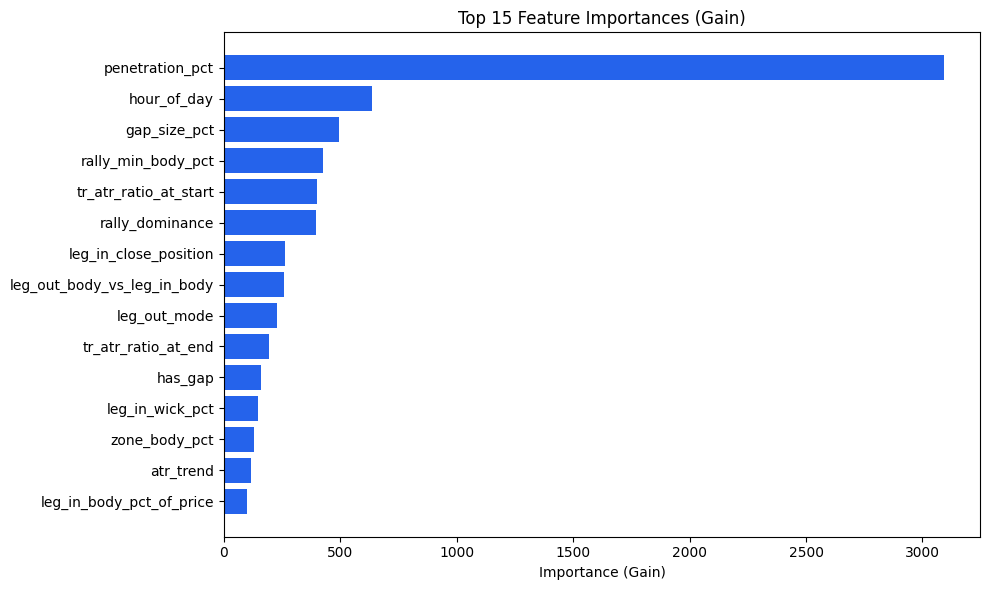

Feature importance chart saved as feature_importance.png


In [10]:
importance_table = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': trained_model.feature_importance(importance_type='gain')
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

print('--- Top 15 Most Important Features (Gain) ---')
print(importance_table.head(15).to_string(index=False))

# Plot bar chart
plt.figure(figsize=(10, 6))
top_15_features = importance_table.head(15).iloc[::-1]
plt.barh(top_15_features['Feature'], top_15_features['Importance'], color='#2563eb')
plt.title('Top 15 Feature Importances (Gain)')
plt.xlabel('Importance (Gain)')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

print('Feature importance chart saved as feature_importance.png')

## 11. Save & Download `model.txt`

Saves the trained model in native LightGBM format and provides a download cell for Google Colab.

In [12]:
model_save_path = 'model.txt'
trained_model.save_model(model_save_path)
print(f'Model successfully saved to {model_save_path}')

# If running in Google Colab, trigger automatic download
if files is not None:
    print('Downloading model.txt and feature_importance.png...')
    files.download('model.txt')
    files.download('feature_importance.png')

Model successfully saved to model.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>